In [2538]:
import sys

In [2539]:
sys.path.append("/Users/paul.vines/Development/motif/ML/field-qualification/")

In [2540]:
from importlib import reload
import feature_extract as fe

reload(fe)
import json
from collections import defaultdict
import itertools as it
import random
import numpy as np
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from collections import Counter, OrderedDict
import pandas as pd
import QualifierPipeline as qp
import os
import models.utils
import models.data_read as data_read

reload(data_read)
reload(models.utils)
import models.decision_tree as dt

reload(dt)
import models.ensemble_binary_decisiton_tree as edt

reload(edt)
import featurization.labels as labels

reload(labels)
reload(qp)

<module 'QualifierPipeline' from '/Users/paul.vines/Development/motif/ML/field-qualification/qualifier-pipeline/QualifierPipeline.py'>

In [2541]:
# features = [
#         "from_src",
#         "unique_score",
#         "is_unique",
#         "is_constant",
#         "entropy",
#         "length_min",
#         "length_max",
#         "length_average",
#         "length_stddev",
#         "length_range",
#         "is_length_constant",
#         "percent_increase",
#         "percent_decrease",
#         "global_unique_score",
#         "global_is_unique",
#         "global_is_constant",
#         "global_entropy",
#         "global_length_min",
#         "global_length_max",
#         "global_length_average",
#         "global_length_stddev",
#         "global_length_range",
#         "global_is_length_constant"
# ]
feature_args = {
    # 'all': None,
    "greg-opt": [
        "unique_score",
        "is_constant",
        "entropy",
        "length_min",
        "length_max",
        "is_length_constant",
        "percent_increase",
        "global_unique_score",
        "global_entropy",
        "global_length_max",
        "global_length_min",
        "global_is_constant",
        "global_is_length_constant",
        "unique_count_debug",
    ],
    # "paul-min": [
    #     "is_unique",
    #     "entropy",
    #     "length_average",
    #     "percent_increase",
    #     "global_unique_score",
    # ],
}

In [2542]:
cluster_args = [
    # (
    #     "KMeans",
    #     KMeans,
    #     {"n_clusters": 10},
    # ),  # set n_clusters to the number of semantic-labels
    # (
    #     "KMeansOversized",
    #     KMeans,
    #     {"n_clusters": 15},
    # ),  # set n_clusters to the number of semantic-labels
    # ("DBSCAN", DBSCAN, None),
]
classifier_args = [
    (
        "EnsembleDecisionTree",
        {},
        {},
    ),
]

# TREES AND CLUSTERING MAX SAMPLE

In [2543]:
top_n = 15

In [2544]:
rtp_files = glob.glob(f"../remora-datasets/csv/*rtp*.csv")
quic_files = glob.glob(f"../remora-datasets/csv/*quic*.csv")
dnp3_files = glob.glob(f"../remora-datasets/csv/*dnp3*.csv")
X_train, y_train, field_names_train = data_read.create_dataset(rtp_files + quic_files)
X_test, y_test, field_names_test = data_read.create_dataset(dnp3_files)
data_bundle = (X_train, y_train, field_names_train, X_test, None, field_names_test)

results = qp.run_pipeline(
    *data_bundle,
    cluster_args=cluster_args,
    classifier_args=classifier_args,
    feature_args=feature_args
)

for fieldname in set(field_names_test):
    x = Counter([tuple(labelset) for labelset in results.loc[results.field == fieldname].labelset]).most_common(top_n)
    print(f'{fieldname}:')
    for labelset in x:
        print(labelset)
    
    print()

combo_max = results

classifier_args=[('EnsembleDecisionTree', {}, {})]
EnsembleDecisionTree
True
removing 16451
Class Balance: 18 / 36
removing 10557
Class Balance: 2965 / 5930
removing 4999
Class Balance: 5744 / 11488
removing 9293
Class Balance: 3597 / 7194
removing 4999
Class Balance: 5744 / 11488
removing 10557
Class Balance: 2965 / 5930
removing 9293
Class Balance: 3597 / 7194
removing 16451
Class Balance: 18 / 36
dnp3.src:
(('id', 'length'), 283)
(('constant', 'length'), 41)

dnp3.ctl.fcv:
(('flag', 'constant'), 312)
(('flag',), 7)
(('sequence', 'flag'), 4)

dnp3.len:
(('length',), 105)
(('sequence', 'flag', 'length'), 88)
(('flag', 'length'), 63)
(('constant', 'length'), 41)
(('flag', 'encrypted', 'length'), 21)
(('sequence', 'flag', 'encrypted', 'length'), 6)

dnp3.tr.ctl:
(('length',), 121)
(('flag', 'encrypted', 'length'), 79)
(('sequence', 'flag', 'encrypted', 'length'), 73)
(('constant', 'length'), 46)
(('flag', 'length'), 1)

dnp.data_chunk:
(('encrypted',), 139)
(('sequence', 'encrypted'), 8

In [2545]:
sampled_prefix="sampled-min10"

In [2546]:
reload(edt)

<module 'models.ensemble_binary_decisiton_tree' from '/Users/paul.vines/Development/motif/ML/field-qualification/models/ensemble_binary_decisiton_tree.py'>

# TREES AND CLUSTERING min10 Sample

In [2547]:
rtp_files = glob.glob(f"../remora-datasets/{sampled_prefix}-csv/*rtp*.csv")
quic_files = glob.glob(f"../remora-datasets/{sampled_prefix}-csv/*quic*.csv")
dnp3_files = glob.glob(f"../remora-datasets/{sampled_prefix}-csv/*dnp3*.csv")
X_train, y_train, field_names_train = data_read.create_dataset(rtp_files + quic_files)
X_test, y_test, field_names_test = data_read.create_dataset(dnp3_files)
data_bundle = (X_train, y_train, field_names_train, X_test, None, field_names_test)

results = qp.run_pipeline(
    *data_bundle,
    cluster_args=cluster_args,
    classifier_args=classifier_args,
    feature_args=feature_args
)

for fieldname in set(field_names_test):
    x = Counter([tuple(labelset) for labelset in results.loc[results.field == fieldname].labelset]).most_common(top_n)
    print(f'{fieldname}:')
    for labelset in x:
        print(labelset)
    
    print()

combo_sample = results

classifier_args=[('EnsembleDecisionTree', {}, {})]
EnsembleDecisionTree
True
removing 956
Class Balance: 12 / 24
removing 266
Class Balance: 357 / 714
removing 922
Class Balance: 29 / 58
removing 242
Class Balance: 369 / 738
removing 922
Class Balance: 29 / 58
removing 266
Class Balance: 357 / 714
removing 242
Class Balance: 369 / 738
removing 956
Class Balance: 12 / 24
dnp3.src:
(('id', 'sequence', 'flag', 'length'), 32)

dnp3.ctl.fcv:
(('sequence', 'flag', 'length'), 31)

dnp3.len:
(('sequence', 'flag', 'length'), 25)
(('flag', 'length'), 7)

dnp3.tr.ctl:
(('sequence', 'flag', 'encrypted', 'length'), 27)
(('sequence', 'length'), 4)

dnp.data_chunk:
(('encrypted', 'length'), 36)
(('sequence', 'encrypted', 'length'), 20)
(('length',), 4)
(('sequence', 'length'), 1)

dnp3.tr.fin:
(('sequence', 'flag', 'length'), 31)

dnp3.dst:
(('id', 'sequence', 'flag', 'length'), 29)
(('sequence', 'flag', 'length'), 3)

dnp3.ctl.secfunc:
(('sequence', 'flag', 'length'), 1)

dnp3.ctl.dfc:
(('sequence',

In [2551]:
def print_results_for_field(fieldname, df):
    aggregate = set()
    for technique in df.technique.unique():
        for featureset in df.featureset.unique():
            x = Counter([tuple(labelset) for labelset in 
                         df.loc[df.field == fieldname].loc[df.technique == technique].loc[df.featureset==featureset].labelset]).most_common(1)

            for labelset in x:
                print(f"{technique}-{featureset}: {labelset}")
                aggregate.update(labelset[0])

    return aggregate

In [2552]:
print_results_for_field('dnp3.start', just_trees_max)

EnsembleDecisionTree-greg-opt: (('constant', 'length'), 324)


{'constant', 'length'}

In [2553]:
def examine_field(fieldname, 
                  just_trees_max=just_trees_max, 
                  combo_max=combo_max,
                  just_trees_sample=just_trees_sample,
                  combo_sample=combo_sample):

    aggregate = set()
    print("\ncombo_max")
    aggregate.update(print_results_for_field(fieldname, combo_max))

    print("\ncombo_sample")
    aggregate.update(print_results_for_field(fieldname, combo_sample))

    return aggregate
    # x = Counter([tuple(labelset) for labelset in 
    #              just_trees_max.loc[just_trees_max.field == fieldname].labelset]).most_common(3)
    # print('just_trees_max')
    # for labelset in x:
    #     print(labelset)
    
    # x = Counter([tuple(labelset) for labelset in 
    #              combo_max.loc[combo_max.field == fieldname].labelset]).most_common(3)
    # print('combo_max')
    # for labelset in x:
    #     print(labelset)

    # x = Counter([tuple(labelset) for labelset in 
    #              just_trees_sample.loc[just_trees_sample.field == fieldname].labelset]).most_common(3)
    # print('just_trees_sample')
    # for labelset in x:
    #     print(labelset)
        
    # x = Counter([tuple(labelset) for labelset in 
    #              combo_sample.loc[combo_sample.field == fieldname].labelset]).most_common(3)
    # print('combo_sample')
    # for labelset in x:
    #     print(labelset)

In [2554]:
set(field_names_test)

{'dnp.data_chunk',
 'dnp.data_chunk.CRC',
 'dnp3.addr',
 'dnp3.ctl',
 'dnp3.ctl.dfc',
 'dnp3.ctl.dir',
 'dnp3.ctl.fcb',
 'dnp3.ctl.fcv',
 'dnp3.ctl.prifunc',
 'dnp3.ctl.prm',
 'dnp3.ctl.secfunc',
 'dnp3.dst',
 'dnp3.hdr.CRC',
 'dnp3.len',
 'dnp3.src',
 'dnp3.start',
 'dnp3.tr.ctl',
 'dnp3.tr.fin',
 'dnp3.tr.fir',
 'dnp3.tr.seq'}

In [2555]:
examine_field('dnp3.len')


combo_max
EnsembleDecisionTree-greg-opt: (('length',), 105)

combo_sample
EnsembleDecisionTree-greg-opt: (('sequence', 'flag', 'length'), 25)


{'flag', 'length', 'sequence'}

In [2556]:
decisions = {}
for fieldname in set(field_names_test):
    print(f"===={fieldname}=====")
    decisions[fieldname] = examine_field(fieldname)
    print(f"====\n")

====dnp3.src=====

combo_max
EnsembleDecisionTree-greg-opt: (('id', 'length'), 283)

combo_sample
EnsembleDecisionTree-greg-opt: (('id', 'sequence', 'flag', 'length'), 32)
====

====dnp3.ctl.fcv=====

combo_max
EnsembleDecisionTree-greg-opt: (('flag', 'constant'), 312)

combo_sample
EnsembleDecisionTree-greg-opt: (('sequence', 'flag', 'length'), 31)
====

====dnp3.len=====

combo_max
EnsembleDecisionTree-greg-opt: (('length',), 105)

combo_sample
EnsembleDecisionTree-greg-opt: (('sequence', 'flag', 'length'), 25)
====

====dnp3.tr.ctl=====

combo_max
EnsembleDecisionTree-greg-opt: (('length',), 121)

combo_sample
EnsembleDecisionTree-greg-opt: (('sequence', 'flag', 'encrypted', 'length'), 27)
====

====dnp.data_chunk=====

combo_max
EnsembleDecisionTree-greg-opt: (('encrypted',), 139)

combo_sample
EnsembleDecisionTree-greg-opt: (('encrypted', 'length'), 36)
====

====dnp3.tr.fin=====

combo_max
EnsembleDecisionTree-greg-opt: (('flag', 'constant'), 296)

combo_sample
EnsembleDecisionTr

In [2557]:
for fieldname, labelset in decisions.items():
    if manual_decisions[fieldname] not in labelset:
        print(f"WRONG: {fieldname} labeled as {labelset} but actually {manual_decisions[fieldname]}")
    elif len(labelset) > 1 and manual_decisions[fieldname] != 'constant':
        print(f"Superset: {fieldname} labeled as {labelset.difference({manual_decisions[fieldname]})} in addition to {manual_decisions[fieldname]}")

Superset: dnp3.src labeled as {'sequence', 'flag', 'length'} in addition to id
Superset: dnp3.ctl.fcv labeled as {'sequence', 'constant', 'length'} in addition to flag
Superset: dnp3.len labeled as {'sequence', 'flag'} in addition to length
Superset: dnp3.tr.ctl labeled as {'sequence', 'flag', 'encrypted'} in addition to length
Superset: dnp.data_chunk labeled as {'length'} in addition to encrypted
Superset: dnp3.tr.fin labeled as {'sequence', 'constant', 'length'} in addition to flag
Superset: dnp3.dst labeled as {'sequence', 'flag', 'length'} in addition to id
Superset: dnp3.ctl.secfunc labeled as {'sequence', 'constant', 'length'} in addition to flag
Superset: dnp3.ctl.prm labeled as {'sequence', 'constant', 'length'} in addition to flag
Superset: dnp3.ctl.dir labeled as {'sequence', 'length'} in addition to flag
WRONG: dnp3.addr labeled as {'flag', 'length'} but actually id
WRONG: dnp3.hdr.CRC labeled as {'sequence', 'flag', 'length', 'id'} but actually encrypted
Superset: dnp3.ctl

# Takaways:
Max-samples are more specific but more often wrong

Look into dnp3.ctl, dnp3.addr, and dnp3.hdr.CRC more

In [2558]:
decisions

{'dnp3.src': {'flag', 'id', 'length', 'sequence'},
 'dnp3.ctl.fcv': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.len': {'flag', 'length', 'sequence'},
 'dnp3.tr.ctl': {'encrypted', 'flag', 'length', 'sequence'},
 'dnp.data_chunk': {'encrypted', 'length'},
 'dnp3.tr.fin': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.dst': {'flag', 'id', 'length', 'sequence'},
 'dnp3.ctl.secfunc': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.ctl.dfc': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.ctl.prm': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.ctl.dir': {'flag', 'length', 'sequence'},
 'dnp3.addr': {'flag', 'length'},
 'dnp3.hdr.CRC': {'flag', 'id', 'length', 'sequence'},
 'dnp3.ctl.prifunc': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.tr.seq': {'encrypted', 'flag', 'length', 'sequence'},
 'dnp3.start': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.tr.fir': {'constant', 'flag', 'length', 'sequence'},
 'dnp3.ctl.fcb': {'constant', 'flag', 'length', 'sequence

In [2559]:
manual_decisions = {'dnp3.src': 'id',
 'dnp3.ctl.fcv': 'flag',
 'dnp3.len': 'length',
 'dnp3.tr.ctl': 'length', # X not sure - probably actually a flag?
 'dnp.data_chunk': 'encrypted',
 'dnp3.tr.fin': 'flag', 
 'dnp3.dst': 'id',
 'dnp3.ctl.secfunc': 'flag',
 'dnp3.ctl.dfc': 'constant', # probably a flag, but if it's constant why not
 'dnp3.ctl.prm': 'flag', 
 'dnp3.ctl.dir': 'flag',
 'dnp3.addr': 'id', # X correction from length
 'dnp3.hdr.CRC': 'encrypted', # X should be ... field? Encrypted? Not length
 'dnp3.ctl.prifunc': 'flag',
 'dnp3.tr.seq': 'sequence', # X should probably be sequence not length
 'dnp3.start': 'constant', # maybe actually length? But effectively constant?
 'dnp3.tr.fir': 'flag', 
 'dnp3.ctl.fcb': 'flag',
 'dnp.data_chunk.CRC': 'encrypted',
 'dnp3.ctl': 'flag'} # X should probably be flag not length

# Heuristic / Linear Classifier Attempts

In [2560]:
import models.data_read as data_read
reload(data_read)
reload(edt)

<module 'models.ensemble_binary_decisiton_tree' from '/Users/paul.vines/Development/motif/ML/field-qualification/models/ensemble_binary_decisiton_tree.py'>

In [2561]:
from sklearn.linear_model import LogisticRegression

In [2562]:
sampled_prefix="sampled-min10-"
# sampled_prefix=""

In [2563]:
rtp_files = glob.glob(f"../remora-datasets/{sampled_prefix}csv/*rtp*.csv")
quic_files = glob.glob(f"../remora-datasets/{sampled_prefix}csv/*quic*.csv")
dnp3_files = glob.glob(f"../remora-datasets/{sampled_prefix}csv/*dnp3*.csv")
X_train, y_train, field_names_train = data_read.create_dataset(rtp_files)
X_test, y_test, field_names_test = data_read.create_dataset(quic_files)
data_bundle = (X_train, y_train, field_names_train, X_test, None, field_names_test)


In [2196]:
set(field_names_test)

{'quic.dcid',
 'quic.dcil',
 'quic.header_form',
 'quic.length',
 'quic.long.packet_type',
 'quic.long.reserved',
 'quic.packet_number',
 'quic.packet_number_length',
 'quic.payload',
 'quic.remaining_payload',
 'quic.scid',
 'quic.scil',
 'quic.token_length',
 'quic.version'}

In [2197]:
reload(edt)

<module 'models.ensemble_binary_decisiton_tree' from '/Users/paul.vines/Development/motif/ML/field-qualification/models/ensemble_binary_decisiton_tree.py'>

In [2211]:
label = "sequence"
clf = edt.LogisticRegressionModel(label, ["percent_increase", "length_stddev"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test)) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 47
Class Balance: 12 / 24
0.9945235487404163 0.9945235487404163


[('length', True),
 ('length', True),
 ('length', True),
 ('length', True),
 ('encrypted', True)]

In [2213]:
label = "encrypted"
clf = edt.LogisticRegressionModel(label, ["unique_score", "global_length_min"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test)) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 39
Class Balance: 16 / 32
1.0 1.0


[]

In [2214]:
#         "from_src",
#         "unique_score",
#         "is_unique",
#         "is_constant",
#         "entropy",
#         "length_min",
#         "length_max",
#         "length_average",
#         "length_stddev",
#         "length_range",
#         "is_length_constant",
#         "percent_increase",
#         "percent_decrease",
#         "global_unique_score",
#         "global_is_unique",
#         "global_is_constant",
#         "global_entropy",
#         "global_length_min",
#         "global_length_max",
#         "global_length_average",
#         "global_length_stddev",
#         "global_length_range",
#         "global_is_length_constant"

In [2203]:
label = "id"
clf = edt.LogisticRegressionModel(label, ["is_constant", "global_is_constant", "is_length_constant", "length_max"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 53
Class Balance: 9 / 18
0.41511500547645125 0.41511500547645125


[('flag', True, 0),
 ('flag', True, 1),
 ('flag', True, 2),
 ('flag', True, 3),
 ('flag', True, 4),
 ('flag', True, 5),
 ('flag', True, 6),
 ('flag', True, 7),
 ('flag', True, 8),
 ('flag', True, 9),
 ('flag', True, 10),
 ('flag', True, 11),
 ('flag', True, 12),
 ('flag', True, 13),
 ('flag', True, 14),
 ('flag', True, 15),
 ('flag', True, 16),
 ('flag', True, 17),
 ('flag', True, 18),
 ('flag', True, 19),
 ('flag', True, 20),
 ('flag', True, 21),
 ('flag', True, 22),
 ('flag', True, 23),
 ('flag', True, 24),
 ('flag', True, 25),
 ('flag', True, 26),
 ('flag', True, 27),
 ('flag', True, 28),
 ('flag', True, 29),
 ('flag', True, 30),
 ('flag', True, 31),
 ('flag', True, 32),
 ('flag', True, 33),
 ('flag', True, 34),
 ('flag', True, 35),
 ('flag', True, 36),
 ('flag', True, 37),
 ('flag', True, 38),
 ('flag', True, 39),
 ('flag', True, 40),
 ('flag', True, 41),
 ('flag', True, 42),
 ('flag', True, 43),
 ('flag', True, 44),
 ('flag', True, 45),
 ('flag', True, 46),
 ('flag', True, 47),
 (

In [2204]:
label = "id"
clf = edt.DecisionTreeModel(label, ["is_constant", "global_is_constant", "is_length_constant", "length_max"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 53
Class Balance: 9 / 18
0.9496166484118291 0.9496166484118291


[('id', False, 188),
 ('id', False, 203),
 ('id', False, 222),
 ('id', False, 248),
 ('id', False, 263),
 ('id', False, 271),
 ('id', False, 277),
 ('id', False, 281),
 ('id', False, 289),
 ('id', False, 304),
 ('length', True, 309),
 ('length', True, 310),
 ('length', True, 311),
 ('length', True, 312),
 ('length', True, 313),
 ('constant', True, 506),
 ('constant', True, 507),
 ('constant', True, 508),
 ('constant', True, 509),
 ('constant', True, 510),
 ('length', True, 511),
 ('length', True, 512),
 ('length', True, 513),
 ('length', True, 514),
 ('length', True, 515),
 ('length', True, 516),
 ('encrypted', True, 517),
 ('id', False, 676),
 ('id', False, 678),
 ('id', False, 681),
 ('id', False, 683),
 ('id', False, 691),
 ('id', False, 694),
 ('id', False, 708),
 ('id', False, 709),
 ('id', False, 711),
 ('id', False, 713),
 ('id', False, 721),
 ('id', False, 728),
 ('id', False, 729),
 ('id', False, 733),
 ('id', False, 735),
 ('id', False, 742),
 ('id', False, 747),
 ('id', Fals

In [2221]:
label = "id"
clf = edt.HeuristicIdModel()
print(1 - len([e for e in zip(y_test, clf.predict(X_train), range(len(X_train))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]) / len(X_train))
clf.predict(X_test)
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

0.9577464788732395


[('constant', True, 506),
 ('constant', True, 507),
 ('constant', True, 508),
 ('constant', True, 509),
 ('constant', True, 510)]

In [2263]:
label = "length"
clf = edt.LogisticRegressionModel(label, ["global_length_max", "global_length_min"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 47
Class Balance: 12 / 24
0.6166484118291348 0.6166484118291348


[('flag', True, 0),
 ('flag', True, 1),
 ('flag', True, 2),
 ('flag', True, 3),
 ('flag', True, 4),
 ('flag', True, 5),
 ('flag', True, 6),
 ('flag', True, 7),
 ('flag', True, 8),
 ('flag', True, 9),
 ('flag', True, 10),
 ('flag', True, 11),
 ('flag', True, 12),
 ('flag', True, 13),
 ('flag', True, 14),
 ('flag', True, 15),
 ('flag', True, 16),
 ('flag', True, 17),
 ('flag', True, 18),
 ('flag', True, 19),
 ('flag', True, 20),
 ('flag', True, 21),
 ('flag', True, 22),
 ('flag', True, 23),
 ('flag', True, 24),
 ('flag', True, 25),
 ('flag', True, 26),
 ('flag', True, 27),
 ('flag', True, 28),
 ('flag', True, 29),
 ('flag', True, 30),
 ('flag', True, 31),
 ('flag', True, 32),
 ('flag', True, 33),
 ('flag', True, 34),
 ('flag', True, 35),
 ('flag', True, 36),
 ('flag', True, 37),
 ('flag', True, 38),
 ('flag', True, 39),
 ('flag', True, 40),
 ('flag', True, 41),
 ('flag', True, 42),
 ('flag', True, 43),
 ('flag', True, 44),
 ('flag', True, 45),
 ('flag', True, 46),
 ('flag', True, 47),
 (

In [2258]:
label = "length"

clf = edt.DecisionTreeModel(label, ["global_length_max"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 47
Class Balance: 12 / 24
0.9989047097480832 0.9989047097480832


[('length', False, 314)]

In [2259]:
print(tree.export_text(clf.clf))

|--- feature_0 <= 24.00
|   |--- feature_0 <= 4.50
|   |   |--- class: False
|   |--- feature_0 >  4.50
|   |   |--- feature_0 <= 12.00
|   |   |   |--- class: True
|   |   |--- feature_0 >  12.00
|   |   |   |--- class: True
|--- feature_0 >  24.00
|   |--- class: False



In [2255]:
label = "flag"
clf = edt.DecisionTreeModel(label, ["is_constant", "global_length_max"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 39
Class Balance: 16 / 32
0.9967141292442497 0.9967141292442497


[('constant', True, 298), ('length', True, 314), ('length', True, 516)]

In [2256]:
from sklearn import tree

In [2257]:
print(tree.export_text(clf.clf))

|--- feature_1 <= 24.00
|   |--- feature_1 <= 4.50
|   |   |--- class: True
|   |--- feature_1 >  4.50
|   |   |--- feature_1 <= 12.00
|   |   |   |--- feature_0 <= 0.50
|   |   |   |   |--- class: True
|   |   |   |--- feature_0 >  0.50
|   |   |   |   |--- class: False
|   |   |--- feature_1 >  12.00
|   |   |   |--- feature_0 <= 0.50
|   |   |   |   |--- class: False
|   |   |   |--- feature_0 >  0.50
|   |   |   |   |--- class: True
|--- feature_1 >  24.00
|   |--- class: False



In [2235]:
clf.clf.tree_.a


AttributeError: 'DecisionTreeClassifier' object has no attribute 'plot_tree'

In [2223]:
label = "flag"
clf = edt.LogisticRegressionModel(label, ["is_constant", "length_max"]).fit(X_train, y_train)
print(clf.score(X_test, y_test), clf.score(X_test, y_test))
[e for e in zip(y_test, clf.predict(X_test), range(len(X_test))) if (not e[1] and e[0] == label) or (e[1] and e[0] != label)]

removing 39
Class Balance: 16 / 32
0.9846659364731654 0.9846659364731654


[('constant', True, 298),
 ('length', True, 309),
 ('length', True, 310),
 ('length', True, 311),
 ('length', True, 312),
 ('length', True, 313),
 ('length', True, 314),
 ('length', True, 511),
 ('length', True, 512),
 ('length', True, 513),
 ('length', True, 514),
 ('length', True, 515),
 ('length', True, 516),
 ('encrypted', True, 517)]

In [2208]:
def details(idx):
    print(field_names_test[idx])
    print(X_test.iloc[idx])

details(506)

quic.version
connection_id                0.000000e+00
from_src                     1.000000e+00
count_debug                  1.000000e+01
unique_count_debug           1.000000e+00
unique_score                 0.000000e+00
is_unique                    1.000000e+00
is_constant                  1.000000e+00
entropy                      0.000000e+00
str_entropy_debug            0.000000e+00
stddev                       0.000000e+00
length_min                   3.200000e+01
length_max                   3.200000e+01
length_average               3.200000e+01
length_stddev                0.000000e+00
length_range                 0.000000e+00
is_length_constant           1.000000e+00
percent_increase             0.000000e+00
percent_decrease             0.000000e+00
range                        0.000000e+00
global_count_debug           1.000000e+03
global_unique_count_debug    2.000000e+00
global_unique_score          2.000000e-03
global_is_unique             0.000000e+00
global_is_constant   

In [2209]:
clf = edt.LogisticRegressionModel("encrypted", ["global_entropy", "entropy", "unique_score"]).fit(X_train, y_train)
print(clf.score(X_train, y_train))
print(clf.score(X_test, y_test))

removing 39
Class Balance: 16 / 32
0.7887323943661971
0.9989047097480832


In [2210]:
clf = edt.DecisionTreeModel("encrypted", ["global_entropy", "entropy", "unique_score"]).fit(X_train, y_train)
print(clf.score(X_train, y_train))
print(clf.score(X_test, y_test))

removing 39
Class Balance: 16 / 32
0.8450704225352113
1.0


# Plotting Attempts (WIP)

In [87]:
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

%matplotlib inline

In [422]:
def plot2d(df, x_axis, y_axis, scoring_function, title="temp-title"):
    # plt.table(celldata_2d)
    # plt.show()
    df = df.set_index([x_axis, y_axis])
    df = df.apply(scoring_function)
    print(x_axis)
    data = [
        [val for val in col[0]]
        for col in df.groupby(by=x_axis).agg(list).values.tolist()
    ]
    print(data)
    sns.heatmap(data)

In [425]:
df.set_index(["srcsamp", "technique"]).groupby(by="srcsamp").agg(list).values.tolist()

[[[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'UNKNOWN'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'UNKNOWN'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant', 'encrypted', 'id'}]],
 [[{'constant',
    'encrypted',
    'flag',
    'id',
    '

In [424]:
plot2d(df, "srcsamp", "technique", lambda x: len(x))

srcsamp


KeyError: 'srcsamp'

In [323]:
df = pd.DataFrame().from_records(
    [
        {"A": "a1", "B": "b1", "C": 11},
        {"A": "a1", "B": "b2", "C": 12},
        {"A": "a2", "B": "b1", "C": 31},
        {"A": "a2", "B": "b2", "C": 32},
    ]
)

In [324]:
df

,A,B,C
0,a1,b1,11
1,a1,b2,12
2,a2,b1,31
3,a2,b2,32


In [325]:
df = df.set_index(["A", "B"])
data = [[val for val in col[0]] for col in df.groupby(by="A").agg(list).values.tolist()]

In [326]:
df

C
A  B     
a1 b1  11
   b2  12
a2 b1  31
   b2  32

In [289]:
data = df.values

In [310]:
df.values.tolist()

[[11], [12], [31], [32]]

In [331]:
data = [[val for val in col[0]] for col in df.groupby(by="A").agg(list).values.tolist()]

In [278]:
import seaborn as sns

<Axes: >

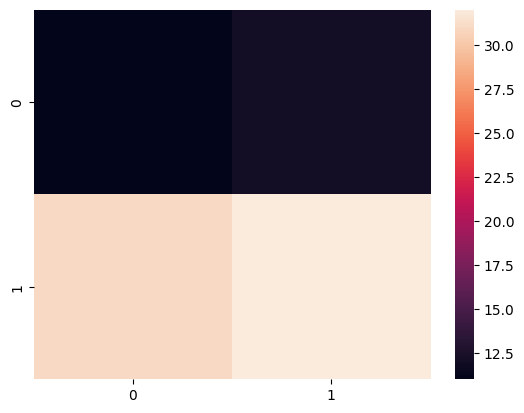

In [332]:
sns.heatmap(data)

In [126]:
df.to_numpy().reshape(4, 3, 1)

array([[['a1'],
        ['b1'],
        ['c11']],

       [['a1'],
        ['b2'],
        ['c12']],

       [['a3'],
        ['b1'],
        ['c31']],

       [['a3'],
        ['b2'],
        ['c32']]], dtype=object)

In [123]:
df.to_numpy().reshape(df.A.nunique(), df.B.nunique(), 1)

ValueError: cannot reshape array of size 12 into shape (2,2,1)

In [121]:
df.nunique

<bound method DataFrame.nunique of     A   B    C
0  a1  b1  c11
1  a1  b2  c12
2  a3  b1  c31
3  a3  b2  c32>

In [116]:
g.describe()

B                     C                 
   count unique top freq count unique  top freq
A                                              
a1     2      2  b1    1     2      2  c11    1
a3     2      2  b1    1     2      2  c31    1

In [112]:
df

,A,B,C
0,a1,b1,c11
1,a1,b2,c12
2,a3,b1,c31
3,a3,b2,c32


KeyError: 0

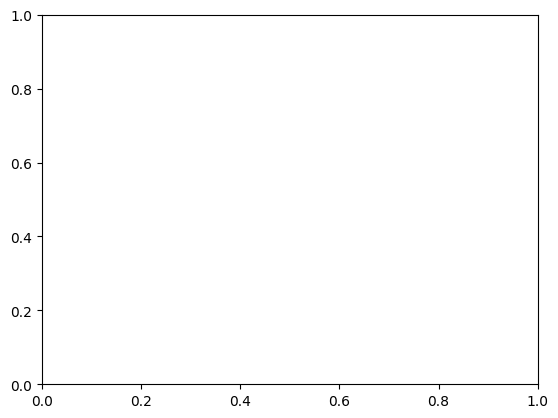

In [90]:
plot2d(df.loc, None)